In [3]:
# 1. Importando as bibliotecas
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 2. Configurando o visual dos gráficos
sns.set_theme(style="whitegrid")

# 3. Lendo os dados das lutas
df_lutas = pd.read_parquet("../data/raw/contests_sample.parquet")

# 4. Mostrando as primeiras 5 linhas e selecionando colunas importantes
colunas_interesse = ['person_white', 'person_blue', 'id_winner', 'duration', 'weight', 'country_white', 'country_blue']
display(df_lutas[colunas_interesse].head())

,person_white,person_blue,id_winner,duration,weight,country_white,country_blue
0,ALATEIK Ghadah,HARANGA HAMAN Audrey,71365,00:01:21,-57,Saudi Arabia,Cameroon
1,PRISO NDOUMBE Darwin,NGOULOU ALEVINA Charles Andre,103642,00:00:21,-73,Cameroon,Gabon
2,TAGYEN Blaise Techwi,YOMBI NINDJEU Rick - Christian,65458,00:03:30,-90,Cameroon,Cameroon
3,NDJIMA EHOWA Raoul,NGOUYASSA BEKAI Denis Cedric,16262,00:03:41,-100,Cameroon,Central African Republic
4,BATIN Emmanuel,WAGUIA KENGMONI Emmanuel Junior,103135,00:00:26,+100,Seychelles,Cameroon


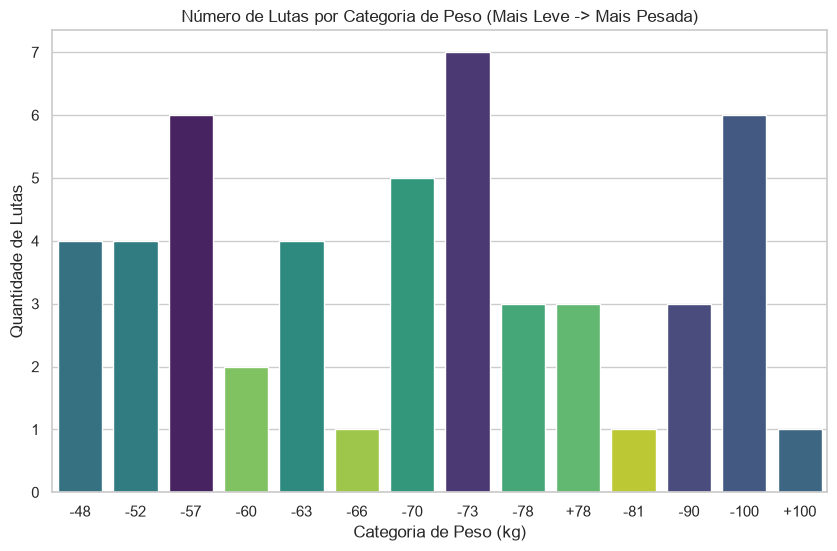

In [12]:
# Função para ordenar as categorias pela "física" do judô
def ordenar_peso(w):
    # Tira o sinal de '-' ou '+', transforma em float e pega o valor absoluto
    numero = abs(float(w.replace('+', '')))
    # Se for categoria com '+', soma 0.1 para garantir que fique no final (mais pesado)
    return numero + (0.1 if w.startswith('+') else 0)

# Pega as categorias únicas e ordena usando a nossa função
categorias = df_lutas['weight'].unique()
categorias_por_peso = sorted(categorias, key=ordenar_peso)

plt.figure(figsize=(10, 6))
sns.countplot(data=df_lutas, x='weight', order=categorias_por_peso, hue='weight', palette='viridis', legend=False)

plt.title('Número de Lutas por Categoria de Peso (Mais Leve -> Mais Pesada)')
plt.xlabel('Categoria de Peso (kg)')
plt.ylabel('Quantidade de Lutas')
plt.show()

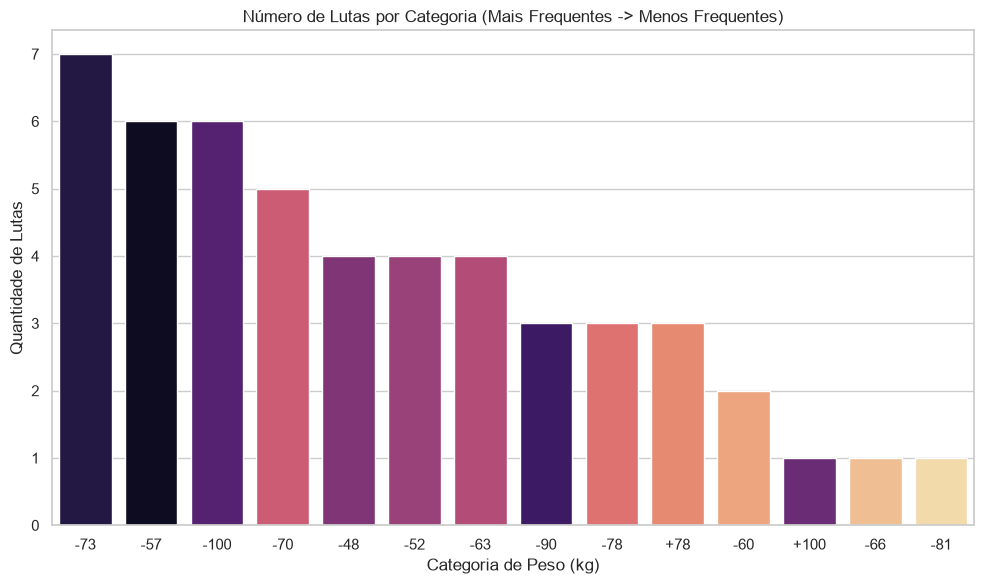

In [14]:
categorias_por_frequencia = df_lutas['weight'].value_counts().index

plt.figure(figsize=(10, 6))
sns.countplot(data=df_lutas, x='weight', order=categorias_por_frequencia, hue='weight', palette='magma', legend=False)

plt.title('Número de Lutas por Categoria (Mais Frequentes -> Menos Frequentes)')
plt.xlabel('Categoria de Peso (kg)')
plt.ylabel('Quantidade de Lutas')
plt.tight_layout()
plt.show()